# Reference-based deconvolution: Xenium lymph node

**Author: Su Xu**

Use fixed reference signatures to estimate named cell-type contributions. This example fits **256 pseudo-spots, 1,027 marker genes and 12 reference types**. The reference consists of raw per-cell arithmetic mean counts on the fitted marker panel. The target is a Xenium lymph-node dataset; the separate Flex reference is not built from target cells. The reference uses library LNReactive_BC9-10 from the public 10x 320k scFFPE Flex release. The donor relationship remains unresolved, so this example is not presented as a verified cross-donor benchmark.

Normalize each reference row to obtain a fixed profile $B$, then optimize only $P$ under the Poisson model. The main RNA reference analysis uses **up to 100,000 steps and KKT tolerance $10^{-10}$**, with spatial weight zero. Those settings are distinct from the 3,000-step independent STARmap sensitivity analysis. Convert molecular weights to estimated cell fractions by dividing each type's contribution by its reference mean library size on the selected genes and renormalizing across all 12 types.

## 1. Set up

Install spDecon using the repository installation instructions, then run this notebook from the cloned repository. The first data-loading cell downloads the versioned data bundle if needed. Saved fits make all plots available on a CPU. Full reference-free training uses the pinned CUDA environment. The saved results are complete fits, not shortened runs. `RUN_FIT=True` executes the full fitting code below; deterministic kernels and a fixed seed support repeatable new fits. Small differences from historical GPU runs may remain.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table
from spDecon.reproducibility import set_seed
set_seed(0, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False


## 2. Load the target and fixed reference

The 1,027-gene panel is the frozen union of the top 100 COSG markers per type (COSG parameter 1). The reference and target share exactly the same gene order. For your own data, compute raw count means by cell type, select markers from the reference, and intersect gene names before fitting.

In [2]:
path, data = dataset("xenium")
x = pd.DataFrame(data["Y"],index=data["spots"],columns=data["genes"])
reference = pd.DataFrame(data["reference"],index=data["types"],columns=data["genes"])
graph = np.load(path/"graph.npz")
print("Target:",x.shape,"Reference:",reference.shape)
display(reference.iloc[:5,:5])

Target: (256, 1027) Reference: (12, 1027)


,ABCA1,ABCB1,ABCB4,ABCC3,ABCC4
CAF,0.734909,0.006830,0.008997,1.049548,0.084843
B,0.133886,0.047261,0.201018,0.014218,0.102982
Plasma,0.068069,0.003289,0.006790,0.051633,0.028203
CD4T,0.046225,0.015380,0.002997,0.009879,0.098976
Macrophage,4.208190,0.006877,0.087172,0.521446,0.116288


## 3. Estimate weights and convert to cell fractions

The fixed-profile optimization is deterministic from a uniform initial mixture. Retaining all fitted types in the denominator matters even when only seven groups are scored.

In [3]:
from spDecon.reference_spatial import fit as fit_fixed_reference
from spDecon.reference import cell_fractions
if RUN_FIT:
    p,b,history,diagnostics = fit_fixed_reference(
        x,reference,graph["edge_i"],graph["edge_j"],graph["weight"],0.,
        tolerance=1e-10,max_steps=100000)
    display(diagnostics)
else:
    fitted = np.load(path/"fit.npz")
    p,b = fitted["P"],fitted["B"]
fractions = pd.DataFrame(cell_fractions(p,reference.sum(axis=1).to_numpy()),
                         index=x.index,columns=reference.index)
display(fractions.head())

,CAF,B,Plasma,CD4T,Macrophage,CD8T,DC,Endothelial,NK,High_proliferation,Pericyte,Mast
HCF,0.000000,0.011096,0.011617,0.000000,0.100045,0.141376,0.057450,0.471059,0.029425,0.056779,0.121152,0.000000
HSJ,0.176853,0.063771,0.023897,0.470811,0.021334,0.117263,0.025074,0.069874,0.000079,0.030120,0.000000,0.000924
ETH,0.149861,0.000000,0.006498,0.714344,0.005103,0.099264,0.000250,0.002595,0.004365,0.017313,0.000000,0.000406
AQS,0.184093,0.023648,0.095183,0.175017,0.100160,0.009560,0.003964,0.202414,0.000000,0.205641,0.000000,0.000319
GRS,0.114646,0.038572,0.040927,0.511910,0.008695,0.051241,0.112461,0.096623,0.000000,0.024926,0.000000,0.000000


## 4. Score the seven supported groups

There are 255 spots on the frozen common evaluation support. The target labels are putative transferred annotations; some classes are excluded because correspondence is uncertain. Sum mapped predicted types into the seven groups, keeping the original denominator. Do not renormalize these seven columns.

,group,PCC
0,B,0.970574
1,Plasma,0.938289
2,DC,0.843121
3,CD4T,0.876134
4,CD8T,0.333950
5,Macrophage,0.838579
6,Mast,0.925952


Mean PCC = 0.818086; RMSE = 0.063448; n = 255


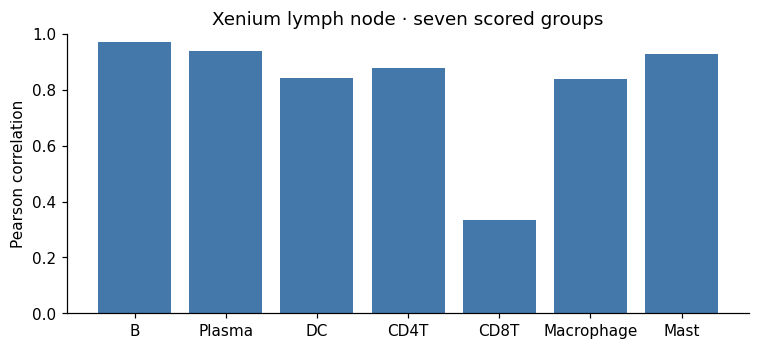

In [4]:
groups = json.loads((path/"scoring_groups.json").read_text())
truth = pd.DataFrame(data["truth"],index=data["truth_spots"],columns=data["truth_types"])
predicted = pd.DataFrame({name:fractions[groups[name]["prediction_types"]].sum(axis=1)
                          for name in truth.columns}).loc[truth.index]
values = np.diag(correlation(predicted.to_numpy(),truth.to_numpy()))
scores = pd.DataFrame({"group":truth.columns,"PCC":values})
display(save_table(scores,"xenium_group_correlations"))
print(f"Mean PCC = {values.mean():.6f}; RMSE = {np.sqrt(np.mean((predicted.to_numpy()-truth.to_numpy())**2)):.6f}; n = {len(truth)}")
fig,ax=plt.subplots(figsize=(8,3.3))
ax.bar(scores.group,scores.PCC,color="#4477AA")
ax.set(ylim=(0,1),ylabel="Pearson correlation",title="Xenium lymph node · seven scored groups")
save_figure(fig,"xenium_correlations")

## 5. Inspect the B- and T-cell distributions

The displayed fractions use all 256 fitted spots and the common 0–1 scale. These maps are predictions, not ground-truth anatomical segmentation.

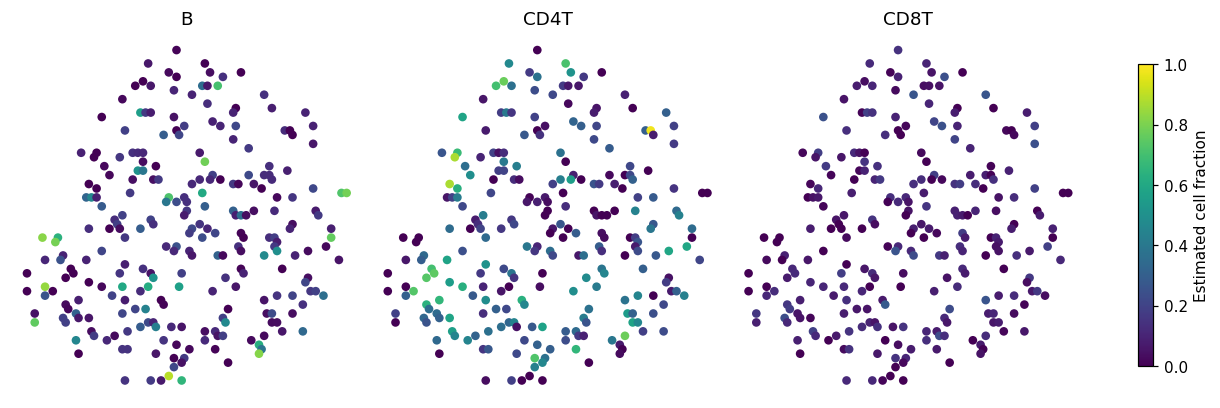

In [5]:
fig,axes=plt.subplots(1,3,figsize=(11,4),layout="constrained")
for ax,name in zip(axes,["B","CD4T","CD8T"]):
    art=spatial(ax,data["coordinates"],fractions[name].to_numpy(),name,size=32)
fig.colorbar(art,ax=axes,label="Estimated cell fraction",shrink=.7)
save_figure(fig,"xenium_maps")
out=ROOT/"outputs/xenium";out.mkdir(parents=True,exist_ok=True)
fractions.to_csv(out/"cell_fractions.csv")